# FL-PERF-002.5 — Scalability analysis and KPI check

*Epic EPIC-001 · story fl_perf_002 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Fit scaling exponents, check story KPIs, and discuss limits; cost figures use labelled illustrative price assumptions.

## 2. Scientific background
Performance of privacy-preserving FL is dominated by cryptographic computation and ciphertext/mask expansion [kairouz2021, li2020challenges]. All clients here are virtual and share one machine, so wall time includes serial execution of clients.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** What are the training-time, communication, memory and CPU overheads of each secure aggregation mechanism?
- **RQ2.** Are the story KPIs (<30% training overhead, <40% communication overhead, <1 pp accuracy loss) met?

## 4. Hypotheses
- **H1.** Secure aggregation overhead exceeds the 30%/40% KPIs for at least some mechanisms in simulation.

## 5. Mathematical formulation
overhead% = 100(x_secure − x_plain)/x_plain; throughput = samples processed / client compute seconds; scaling exponent b from log-log fit time ∝ n^b.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_perf_002"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_perf_002


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`monitoring.py`, `fl.py`, `crypto/*`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
from federated_learning.monitoring.resources import ResourceMonitor
parts = partition_iid(data.y_train, 5, SEED)
with ResourceMonitor(0.02) as m:
    r = run_fl(FLConfig(rounds=3, local_epochs=1, seed=SEED), data, parts)
s = m.summary(); print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in s.items()})
assert s["cpu_time_s"] > 0 and s["wall_s"] > 0

{'wall_s': 0.14, 'cpu_time_s': 0.14, 'cpu_util_mean_pct': 97.117, 'cpu_util_peak_pct': 98.2, 'rss_mean_mb': 740.371, 'rss_peak_mb': 741.98, 'n_samples': 6, 'sample_interval_s': 0.02, 'gpu_available': False, 'gpu_util_pct': None, 'gpu_mem_mb': None}


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-PERF-002.5` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_2_5_scalability_table.csv')
show_csv('task_2_5_scaling_exponents.csv')
show_csv('task_2_5_kpi_check.csv')

,config,n_clients,runs,train_wall_s,mean_round_s,client_time_s,agg_time_s,up_mb,down_mb,comm_mb_per_round,cpu_time_s,cpu_util_mean_pct,rss_peak_mb,throughput_samples_per_s,acc,train_overhead_pct,comm_overhead_pct,acc_loss_pp,agg_share_of_round,est_cost_usd_per_run
0,plain,10,3,1.4471,0.1447,1.4320,0.0020,0.5257,0.5257,0.1051,1.4400,99.5664,899.1198,59383.6345,0.7774,NaN,NaN,NaN,0.0014,0.0001
1,plain,50,3,1.6474,0.1647,1.6302,0.0041,2.6283,2.6283,0.5257,1.6400,99.1470,998.3255,51993.2012,0.6805,NaN,NaN,NaN,0.0025,0.0005
2,plain,100,2,1.8427,0.1843,1.8176,0.0084,5.2567,5.2567,1.0513,1.8150,98.0632,1006.8945,46241.4013,0.6214,NaN,NaN,NaN,0.0046,0.0009
3,plain,500,1,3.9800,0.3980,3.9082,0.0387,26.2833,26.2833,5.2567,3.9100,97.9923,1027.6484,21493.3536,0.5350,NaN,NaN,NaN,0.0097,0.0047
4,secagg_complete,10,3,1.6555,0.1655,1.3812,0.2632,1.2672,0.7248,0.1992,1.6500,99.5432,934.7109,60831.4277,0.7774,15.6761,89.4775,0.0,0.1590,0.0002
5,secagg_complete,50,3,9.8501,0.9850,1.8267,8.0071,10.8376,8.0490,1.8887,9.8200,100.0655,999.2070,46402.1618,0.6805,507.0469,259.2888,0.0,0.8129,0.0018
6,secagg_complete,100,2,39.5823,3.9582,1.9105,37.6548,32.9285,27.1606,6.0089,39.4100,100.2844,1010.2344,43996.1418,0.6214,2050.0639,471.5530,0.0,0.9513,0.0057
7,he_ckks,10,3,2.5495,0.2550,1.4499,1.0845,31.5961,0.5257,3.2122,2.5333,101.7924,978.4740,58151.6139,0.7774,77.1199,2955.3429,0.0,0.4254,0.0029
8,he_ckks,50,3,7.5447,0.7545,1.8077,5.7209,158.0665,2.6283,16.0695,7.4800,100.2505,1004.9661,46474.4210,0.6805,361.4532,2956.9802,0.0,0.7583,0.0142
9,he_ckks,100,2,12.3395,1.2339,1.8834,10.4357,316.0000,5.2567,32.1257,12.2350,99.6433,1026.4102,44603.7472,0.6214,570.2023,2955.7148,0.0,0.8457,0.0284


,config,loglog_slope,points,note
0,plain,0.2557,4,slope~1 linear in n; slope~2 quadratic (empiri...
1,secagg_complete,1.3309,3,slope~1 linear in n; slope~2 quadratic (empiri...
2,he_ckks,0.7905,4,slope~1 linear in n; slope~2 quadratic (empiri...
3,smpc_3party,0.8699,4,slope~1 linear in n; slope~2 quadratic (empiri...


,config,n_clients,training_overhead_pct,target_lt_30,comm_overhead_pct,target_lt_40,accuracy_loss_pp,target_lt_1
0,secagg_complete,10,15.6761,True,89.4775,False,0.0,True
1,secagg_complete,50,507.0469,False,259.2888,False,0.0,True
2,secagg_complete,100,2050.0639,False,471.5530,False,0.0,True
3,he_ckks,10,77.1199,False,2955.3429,False,0.0,True
4,he_ckks,50,361.4532,False,2956.9802,False,0.0,True
5,he_ckks,100,570.2023,False,2955.7148,False,0.0,True
6,he_ckks,500,1325.5695,False,2956.4369,False,0.0,True
7,smpc_3party,10,104.5352,False,250.0000,False,0.0,True
8,smpc_3party,50,490.7526,False,250.0000,False,0.0,True
9,smpc_3party,100,962.8699,False,250.0000,False,0.0,True


## 12. Metrics collection
Metric definitions: Defined in `monitoring.py` docstring and docs/fl_perf_002/metrics_definitions.md: cpu_time_s (cumulative), cpu util mean/peak, RSS mean/peak, logical comm bytes, GPU = unavailable (never estimated).

In [8]:
show_csv('task_2_5_scalability_table.csv')

,config,n_clients,runs,train_wall_s,mean_round_s,client_time_s,agg_time_s,up_mb,down_mb,comm_mb_per_round,cpu_time_s,cpu_util_mean_pct,rss_peak_mb,throughput_samples_per_s,acc,train_overhead_pct,comm_overhead_pct,acc_loss_pp,agg_share_of_round,est_cost_usd_per_run
0,plain,10,3,1.4471,0.1447,1.4320,0.0020,0.5257,0.5257,0.1051,1.4400,99.5664,899.1198,59383.6345,0.7774,NaN,NaN,NaN,0.0014,0.0001
1,plain,50,3,1.6474,0.1647,1.6302,0.0041,2.6283,2.6283,0.5257,1.6400,99.1470,998.3255,51993.2012,0.6805,NaN,NaN,NaN,0.0025,0.0005
2,plain,100,2,1.8427,0.1843,1.8176,0.0084,5.2567,5.2567,1.0513,1.8150,98.0632,1006.8945,46241.4013,0.6214,NaN,NaN,NaN,0.0046,0.0009
3,plain,500,1,3.9800,0.3980,3.9082,0.0387,26.2833,26.2833,5.2567,3.9100,97.9923,1027.6484,21493.3536,0.5350,NaN,NaN,NaN,0.0097,0.0047
4,secagg_complete,10,3,1.6555,0.1655,1.3812,0.2632,1.2672,0.7248,0.1992,1.6500,99.5432,934.7109,60831.4277,0.7774,15.6761,89.4775,0.0,0.1590,0.0002
5,secagg_complete,50,3,9.8501,0.9850,1.8267,8.0071,10.8376,8.0490,1.8887,9.8200,100.0655,999.2070,46402.1618,0.6805,507.0469,259.2888,0.0,0.8129,0.0018
6,secagg_complete,100,2,39.5823,3.9582,1.9105,37.6548,32.9285,27.1606,6.0089,39.4100,100.2844,1010.2344,43996.1418,0.6214,2050.0639,471.5530,0.0,0.9513,0.0057
7,he_ckks,10,3,2.5495,0.2550,1.4499,1.0845,31.5961,0.5257,3.2122,2.5333,101.7924,978.4740,58151.6139,0.7774,77.1199,2955.3429,0.0,0.4254,0.0029
8,he_ckks,50,3,7.5447,0.7545,1.8077,5.7209,158.0665,2.6283,16.0695,7.4800,100.2505,1004.9661,46474.4210,0.6805,361.4532,2956.9802,0.0,0.7583,0.0142
9,he_ckks,100,2,12.3395,1.2339,1.8834,10.4357,316.0000,5.2567,32.1257,12.2350,99.6433,1026.4102,44603.7472,0.6214,570.2023,2955.7148,0.0,0.8457,0.0284


## 13. Statistical analysis
Repeated seeds per configuration; CIs from t-distribution/bootstrap; no significance claims beyond CIs.

In [9]:
show_csv('task_2_5_kpi_check.csv', 15)

,config,n_clients,training_overhead_pct,target_lt_30,comm_overhead_pct,target_lt_40,accuracy_loss_pp,target_lt_1
0,secagg_complete,10,15.6761,True,89.4775,False,0.0,True
1,secagg_complete,50,507.0469,False,259.2888,False,0.0,True
2,secagg_complete,100,2050.0639,False,471.5530,False,0.0,True
3,he_ckks,10,77.1199,False,2955.3429,False,0.0,True
4,he_ckks,50,361.4532,False,2956.9802,False,0.0,True
5,he_ckks,100,570.2023,False,2955.7148,False,0.0,True
6,he_ckks,500,1325.5695,False,2956.4369,False,0.0,True
7,smpc_3party,10,104.5352,False,250.0000,False,0.0,True
8,smpc_3party,50,490.7526,False,250.0000,False,0.0,True
9,smpc_3party,100,962.8699,False,250.0000,False,0.0,True


## 14. Visualizations

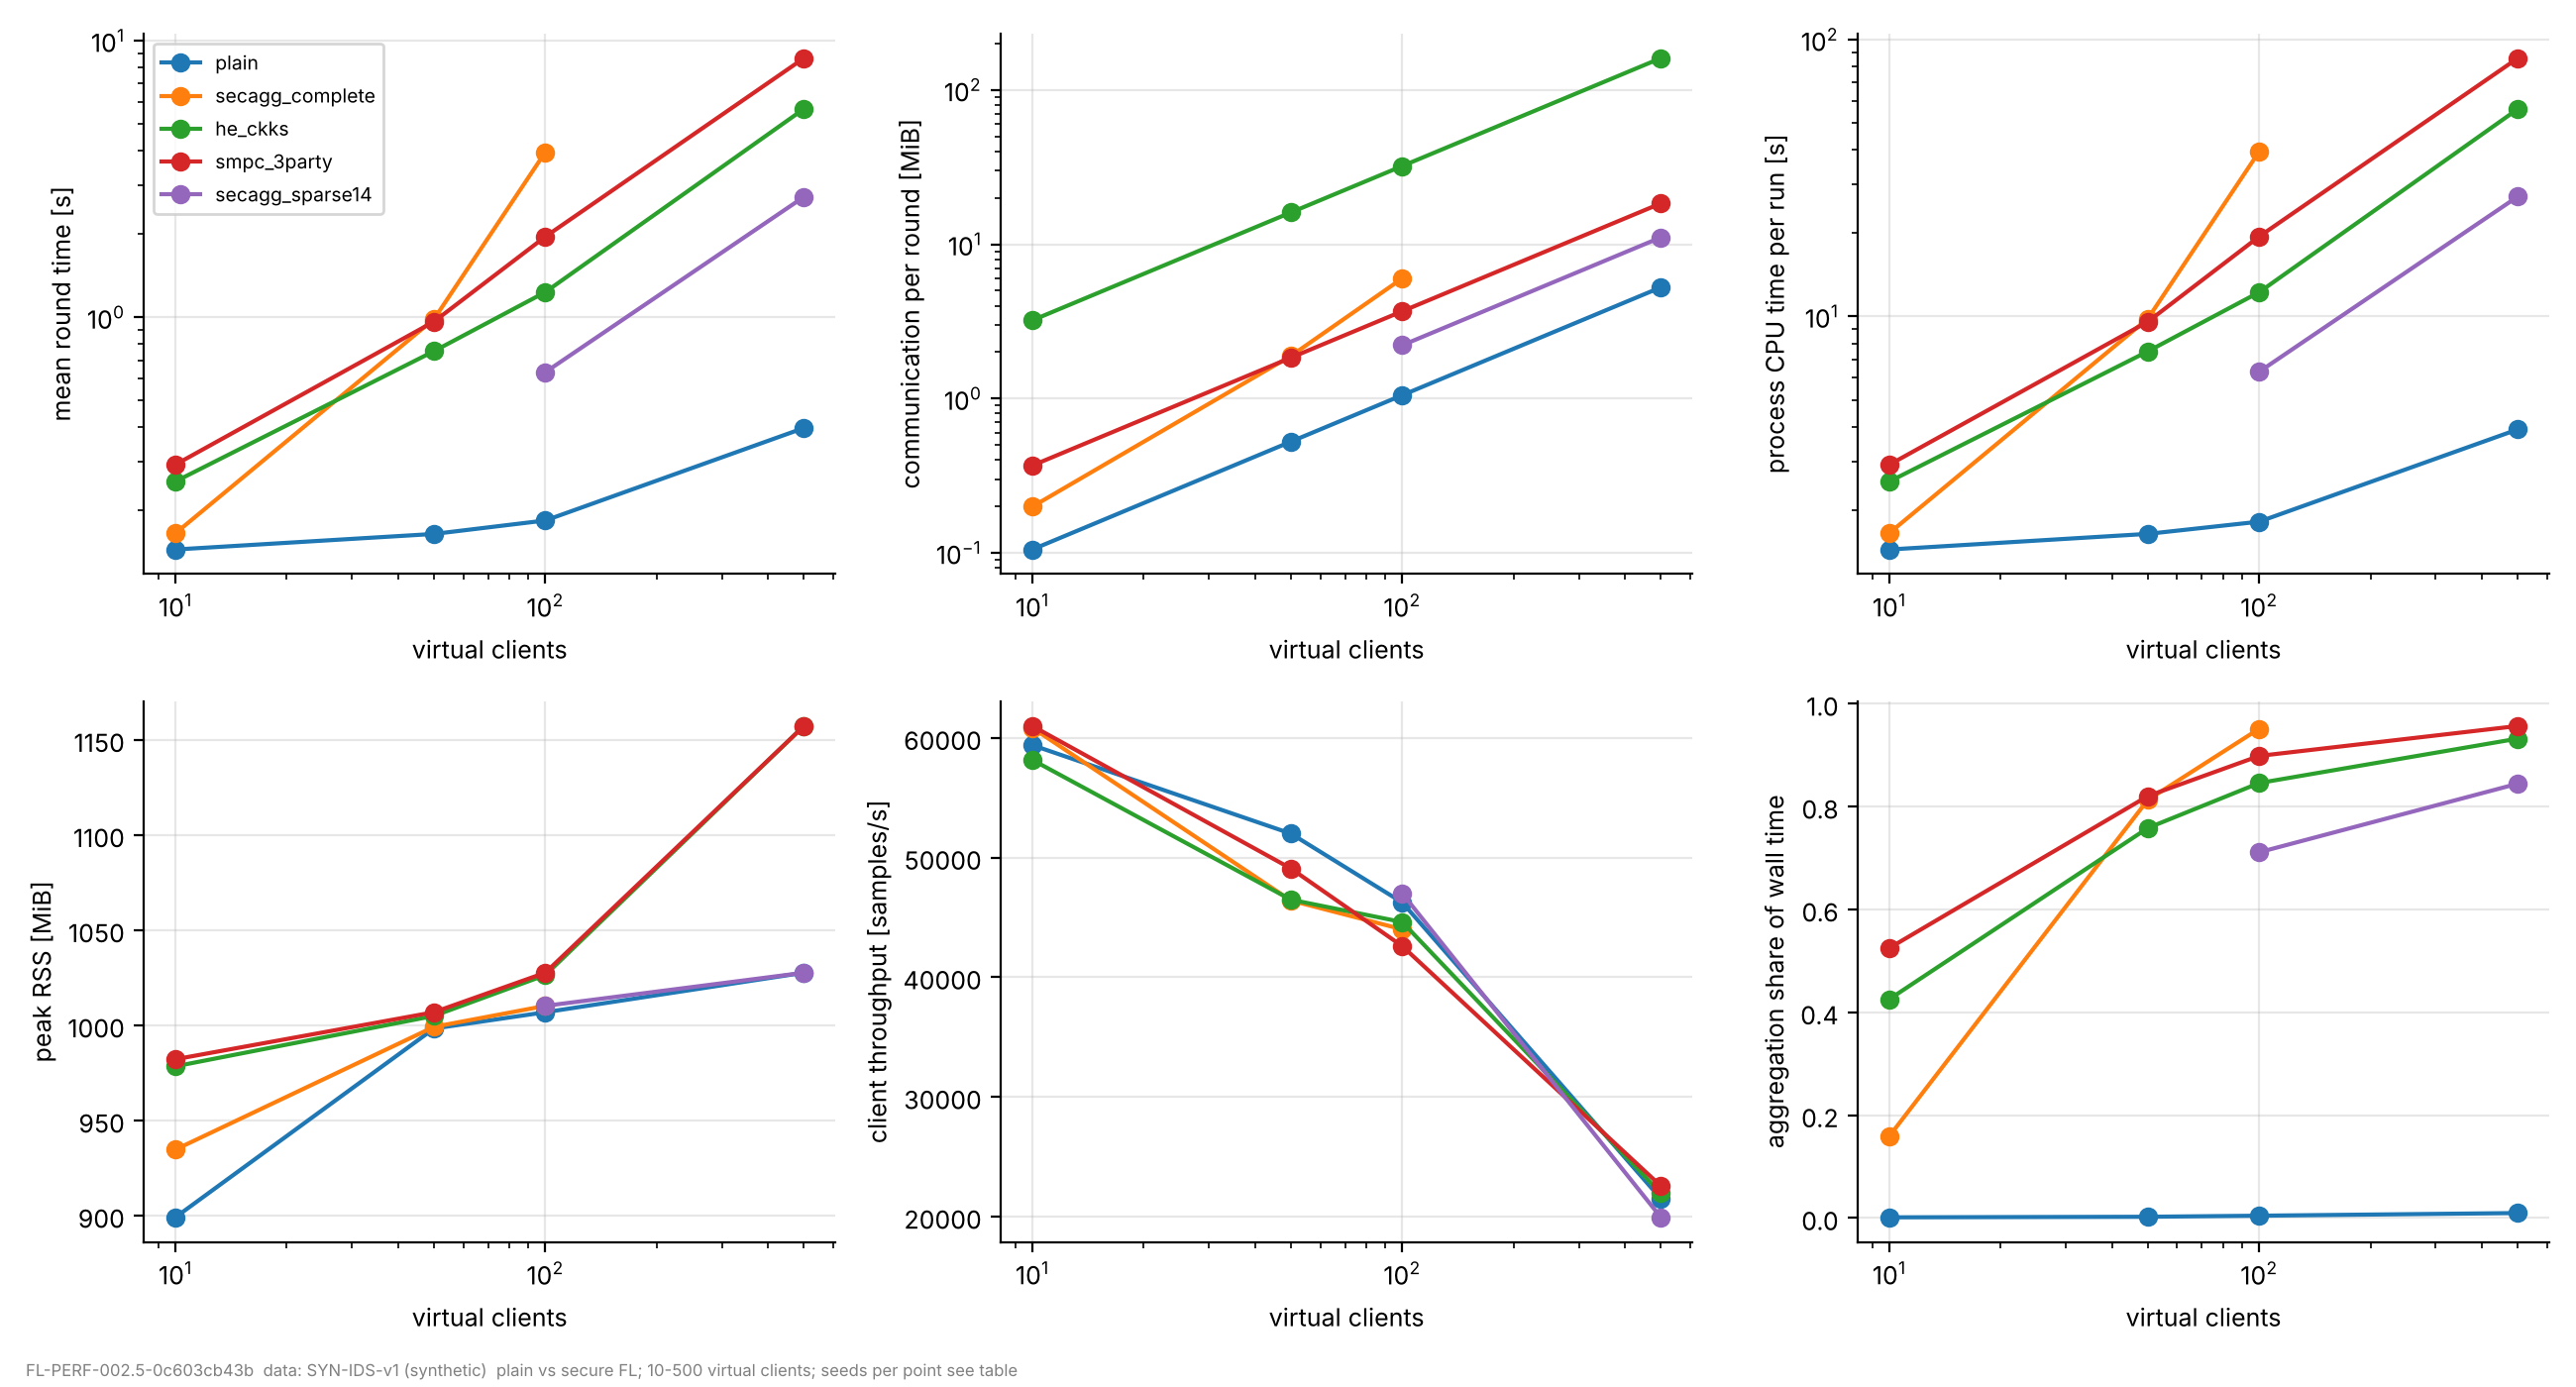

In [10]:
show_fig('task_2_5_scalability_curves.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

KPIs <30% training overhead and <40% communication overhead are mostly NOT MET in this simulation (printed).

In [11]:
d = pd.read_csv(RES / 'task_2_5_kpi_check.csv'); print(d.round(1).to_string(index=False))

         config  n_clients  training_overhead_pct  target_lt_30  comm_overhead_pct  target_lt_40  accuracy_loss_pp  target_lt_1
secagg_complete         10                   15.7          True               89.5         False               0.0         True
secagg_complete         50                  507.0         False              259.3         False               0.0         True
secagg_complete        100                 2050.1         False              471.6         False               0.0         True
        he_ckks         10                   77.1         False             2955.3         False               0.0         True
        he_ckks         50                  361.5         False             2957.0         False               0.0         True
        he_ckks        100                  570.2         False             2955.7         False               0.0         True
        he_ckks        500                 1325.6         False             2956.4         False        

## 16. Limitations
- Virtual clients: time does not reflect parallel hospitals or network latency.
- Price assumptions are illustrative, not quotes.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md for the KPI verdicts; they are reported as measured, including NOT MET.

**Jira acceptance:** see `docs/fl_perf_002/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`kairouz2021`, `li2020challenges`, `bonawitz2017`, `cheon2017` — details in `docs/fl_perf_002/references.md`.